## Segmentimi i klienteve

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.segmentation import scale_features, rfm_quantile_segments

pd.set_option("display.float_format", "{:,.2f}".format)

rfm = pd.read_csv("../data/processed/rfm.csv", index_col="Customer ID")
print(rfm.shape)
rfm.head()

(5852, 3)


,Recency,Frequency,Monetary
Customer ID,,,
12346,326,3,"77,352.96"
12347,3,8,"4,921.53"
12348,76,5,"1,658.40"
12349,19,3,"3,678.69"
12350,311,1,294.40


In [2]:
scaled, scaler = scale_features(rfm)
scaled.describe().round(2)

,Recency_log,Frequency_log,Monetary_log
count,"5,852.00","5,852.00","5,852.00"
mean,-0.00,0.00,-0.00
std,1.00,1.00,1.00
min,-2.47,-1.06,-3.94
25%,-0.77,-1.06,-0.71
50%,0.07,-0.20,-0.04
75%,0.96,0.66,0.66
max,1.40,5.42,4.68


In [3]:
seg = rfm_quantile_segments(rfm)

for col in ["R", "F", "M"]:
    print(col, seg[col].value_counts().sort_index().to_dict())
    
seg["Segment"].value_counts()

R {1: 1171, 2: 1170, 3: 1170, 4: 1170, 5: 1171}
F {1: 1171, 2: 1170, 3: 1170, 4: 1170, 5: 1171}
M {1: 1171, 2: 1170, 3: 1170, 4: 1170, 5: 1171}


Segment
Lost               1511
Loyal              1401
Champions          1280
At risk             830
New                 447
Needs attention     383
Name: count, dtype: int64

In [4]:
profile = rfm.join(seg["Segment"]).groupby("Segment").agg(
    Klientet=("Recency", "size"),
    Recency_mediana=("Recency", "median"),
    Frequency_mediana=("Frequency", "median"),
    Monetary_mediana=("Monetary", "median"),
    Te_ardhurat=("Monetary", "sum")
)

profile["Pjesa_e_klienteve_%"] = profile["Klientet"] / profile["Klientet"].sum() * 100
profile["Pjesa_e_te_ardhuarve_%"] = profile["Te_ardhurat"] / profile["Te_ardhurat"].sum() * 100
profile.sort_values("Te_ardhurat", ascending=False).round(1)

,Klientet,Recency_mediana,Frequency_mediana,Monetary_mediana,Te_ardhurat,Pjesa_e_klienteve_%,Pjesa_e_te_ardhuarve_%
Segment,,,,,,,
Champions,1280,17.00,11.00,"3,903.90","11,602,802.40",21.90,68.00
Loyal,1401,65.00,4.00,"1,082.80","2,631,069.10",23.90,15.40
At risk,830,374.00,4.00,"1,020.50","1,597,027.20",14.20,9.40
Lost,1511,433.00,1.00,277.90,"620,553.60",25.80,3.60
New,447,27.00,1.00,366.20,"411,665.70",7.60,2.40
Needs attention,383,93.00,1.00,358.80,"205,450.00",6.50,1.20


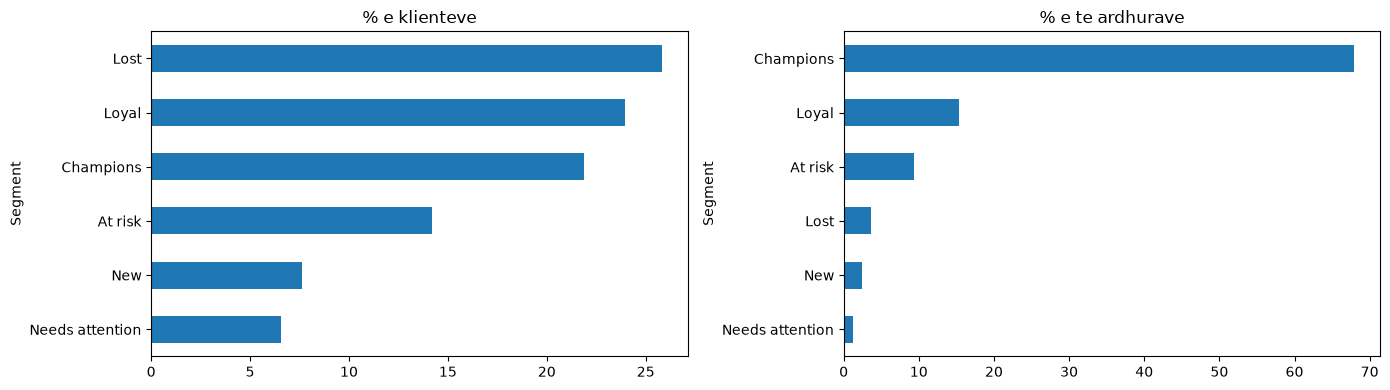

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
profile["Pjesa_e_klienteve_%"].sort_values().plot.barh(ax=axes[0], title="% e klienteve")
profile["Pjesa_e_te_ardhuarve_%"].sort_values().plot.barh(ax=axes[1], title="% e te ardhurave")
plt.tight_layout()
plt.show()

## Segmentimi baze me kuantile RFM (pike krahasimi)

Çdo klient merr pike 1-5 per Recency, Frequency dhe Monetary (kuintile), dhe pastaj nje segment sipas rregullave te thjeshta.

| Segment | Kliente | % e klienteve | % e te ardhurave | Recency (mediana, dite) | Frequency (mediana, fatura) | Monetary (mediana, £) |
|---|---|---|---|---|---|---|
| Champions | 1,280 | 21.9% | 68.0% | 17 | 11 | 3,903.90 |
| Loyal | 1,401 | 23.9% | 15.4% | 65 | 4 | 1,082.80 |
| At risk | 830 | 14.2% | 9.4% | 374 | 4 | 1,020.50 |
| Lost | 1,511 | 25.8% | 3.6% | 433 | 1 | 277.90 |
| New | 447 | 7.6% | 2.4% | 27 | 1 | 366.20 |
| Needs attention | 383 | 6.5% | 1.2% | 93 | 1 | 358.80 |

**Vezhgime**
- Champions jane 21.9% e klienteve (1,280) por sjellin 68.0% te te ardhurave. Nje klient tipik i ketij segmenti ka blere para 17 ditesh, ka 11 fatura dhe ka shpenzuar rreth 3,900 £.
- Champions dhe Loyal se bashku jane 45.8% e klienteve dhe sjellin 83.4% te te ardhurave, pra biznesi mbeshtetet te gjysma e klienteve.
- Lost jane segmenti me i madh per nga numri (25.8%) por sjellin vetem 3.6% te te ardhurave. Mediana eshte 1 fature dhe 433 dite pa bler, pra jane klient qe blen nje here dhe nuk u kthyen.
- At risk eshte segmenti me interesant per biznesin: 830 kliente me mediane 4 fatura dhe rreth 1,020 £ të shpenzuara (afer Loyal), por 374 dite pa bler. Ata kan historik blerjesh, ndaj nje fushat kthimi ka kuptim, dhe kane sjelle rreth 1.6 milion £.
- New (447 kliente) kan bler para 27 ditesh me vetem nje fature. Qellimi eshte t'i çosh te blerja e dyte.
- Kufizim: kufijt e rregullave jane vendosur me dore dhe jane te ngurte, dhe grupet e pikeve ndahen me renditje, jo me vlera te njejta. KMeans do te gjej grupe nga vet te dhenat dhe te dyja metodat do te krahasohen.

## KMeans: zgjedhja e numrit te grupeve

In [6]:
from src.segmentation import evaluate_kmeans

results = evaluate_kmeans(scaled)
results.round(3)

,inertia,silhouette
k,,
2,"8,550.16",0.44
3,"6,320.36",0.35
4,"4,881.99",0.37
5,"4,061.59",0.35
6,"3,528.96",0.34
7,"3,164.04",0.31
8,"2,879.23",0.30
9,"2,632.66",0.29
10,"2,443.11",0.29


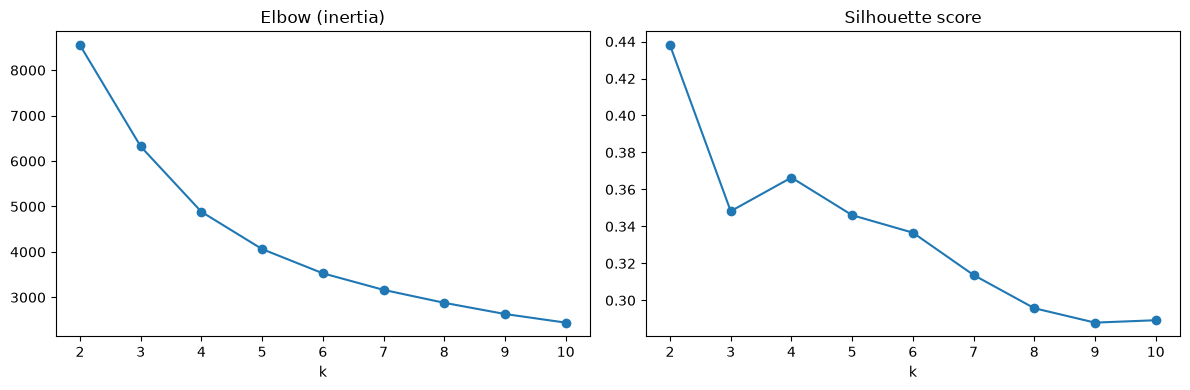

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(results.index, results["inertia"], marker="o")
axes[0].set_title("Elbow (inertia)")
axes[0].set_xlabel("k")
axes[1].plot(results.index, results["silhouette"], marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k")
plt.tight_layout()
plt.show()

In [8]:
from sklearn.cluster import KMeans

for k in [3, 4, 5]:
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(scaled)
    print(k, pd.Series(labels).value_counts().sort_index().to_dict())

3 {0: 1240, 1: 2373, 2: 2239}
4 {0: 1447, 1: 1260, 2: 1191, 3: 1954}
5 {0: 1635, 1: 467, 2: 1286, 3: 1129, 4: 1335}


### Rezultatet e KMeans per k = 2 deri 10

| k | Inertia | Silhouette |
|---|---|---|
| 2 | 8,550.16 | 0.44 |
| 3 | 6,320.36 | 0.35 |
| 4 | 4,881.99 | 0.37 |
| 5 | 4,061.59 | 0.35 |
| 6 | 3,528.96 | 0.34 |
| 7 | 3,164.04 | 0.31 |
| 8 | 2,879.23 | 0.30 |
| 9 | 2,632.66 | 0.29 |
| 10 | 2,443.11 | 0.29 |

**Vezhgime**
- Silhouette eshte me e larta per k = 2 (0.44), por me vetem dy grupe biznesi nuk mund te dallojne veprime te ndryshme per klientet. Per k >= 3 vlera me e larte eshte k = 4 (0.37), pak mbi k = 3 dhe k = 5 (te dyja 0.35). Pas k = 5 silhouette bie ngadale deri ne 0.29.
- Te gjitha vlerat jane mes 0.29 dhe 0.44, pra ndarja eshte e arsyeshme por jo e forte (nuk kalon 0.5). Kjo pritet te RFM, sepse klientet formojne nje vazhdimesi dhe jo grupe plotesisht te ndara.
- Elbow nuk eshte i mprehte. Inertia bie me 26.1% nga k = 2 ne 3, me 22.8% ne 4, me 16.8% ne 5, me 13.1% ne 6, dhe pastaj me me pak se 11% per cdo k te ri (vetem 7.2% nga 9 ne 10). Renia ngadalesohet dukshem pas k = 4 ose 5.
- Madhesite e grupeve (nga 5,852 kliente gjithsej): per k = 3 jane 1,240, 2,373 dhe 2,239; per k = 4 jane 1,447, 1,260, 1,191 dhe 1,954 (me te balancuarat, nga 20.4% deri 33.4%); per k = 5 jane 1,635, 467, 1,286, 1,129 dhe 1,335, ku nje grup eshte mjaft i vogel (467 kliente, 8.0%).
- Kandidatet per vendimin perfundimor jane k = 4 dhe k = 5. Vendimi do te merret pasi te krahasoj profilet e grupeve, jo vetem numrat.

## Zgjedhja e k dhe profilizimi

In [9]:
from sklearn.metrics import adjusted_rand_score, silhouette_score
from src.segmentation import fit_kmeans, fit_hierarchical, profile_cluster, stability_check

profiles = {}
for k in [3,4,5]:
    model, labels = fit_kmeans(scaled, k)
    profiles[k] = profile_cluster(rfm, labels)
    print(f"\n   k = {k}   ")
    display(profiles[k])


   k = 3   


,Klientet,Recency_mediana,Freuqency_mediana,Monetary_mediana,Te_ardhurat,Pjesa_e_klienteve_%,Pjesa_e_te_ardhurave_%
Cluster,,,,,,,
0,1240,17.00,13.00,"4,868.60","12,976,481.70",21.20,76.00
1,2373,395.00,1.00,309.50,"962,664.60",40.60,5.60
2,2239,54.00,4.00,"1,128.50","3,129,421.70",38.30,18.30



   k = 4   


,Klientet,Recency_mediana,Freuqency_mediana,Monetary_mediana,Te_ardhurat,Pjesa_e_klienteve_%,Pjesa_e_te_ardhurave_%
Cluster,,,,,,,
0,1447,185.00,4.00,"1,450.00","2,847,791.40",24.70,16.70
1,1260,24.00,3.00,716.50,"1,055,624.90",21.50,6.20
2,1191,17.00,13.00,"4,890.10","12,547,595.50",20.40,73.50
3,1954,402.00,1.00,273.30,"617,556.30",33.40,3.60



   k = 5   


,Klientet,Recency_mediana,Freuqency_mediana,Monetary_mediana,Te_ardhurat,Pjesa_e_klienteve_%,Pjesa_e_te_ardhurave_%
Cluster,,,,,,,
0,1635,418.00,1.00,239.50,"442,802.60",27.90,2.60
1,467,9.00,23.00,"9,763.20","9,527,870.40",8.00,55.80
2,1286,30.00,8.00,"2,771.30","4,327,632.40",22.00,25.40
3,1129,30.00,2.00,554.60,"713,682.60",19.30,4.20
4,1335,258.00,4.00,"1,117.00","2,056,580.00",22.80,12.00


In [10]:
for k in [3, 4, 5]:
    ari = stability_check(scaled, k)
    print(f"k = {k}: ARI mesatar = {np.mean(ari):.3f} | minimumi = {np.min(ari):.3f}")

k = 3: ARI mesatar = 0.976 | minimumi = 0.967
k = 4: ARI mesatar = 0.998 | minimumi = 0.997
k = 5: ARI mesatar = 0.951 | minimumi = 0.893


In [11]:
k = 4
_, km_labels = fit_kmeans(scaled, k)
hc_labels = fit_hierarchical(scaled, k)

print("Silhouette KMeans:      ", round(silhouette_score(scaled, km_labels), 3))
print("Silhouette Hierarchical:", round(silhouette_score(scaled, hc_labels), 3))
print("ARI KMeans vs Hierarchical:", round(adjusted_rand_score(km_labels, hc_labels), 3))

pd.crosstab(km_labels, hc_labels, rownames=["KMeans"], colnames=["Hierarchical"])

Silhouette KMeans:       0.366
Silhouette Hierarchical: 0.26
ARI KMeans vs Hierarchical: 0.366


Hierarchical,0,1,2,3
KMeans,,,,
0,807,634,0,6
1,530,724,0,6
2,0,739,452,0
3,419,0,0,1535


In [12]:
k = 5
_, km_labels = fit_kmeans(scaled, k)
hc_labels = fit_hierarchical(scaled, k)

print("Silhouette KMeans:      ", round(silhouette_score(scaled, km_labels), 3))
print("Silhouette Hierarchical:", round(silhouette_score(scaled, hc_labels), 3))
print("ARI KMeans vs Hierarchical:", round(adjusted_rand_score(km_labels, hc_labels), 3))

pd.crosstab(km_labels, hc_labels, rownames=["KMeans"], colnames=["Hierarchical"])

Silhouette KMeans:       0.346
Silhouette Hierarchical: 0.28
ARI KMeans vs Hierarchical: 0.597


Hierarchical,0,1,2,3,4
KMeans,,,,,
0,0,1505,0,70,60
1,55,0,412,0,0
2,1243,0,40,0,3
3,489,10,0,630,0
4,310,32,0,64,929


In [13]:
seg = rfm_quantile_segments(rfm)
pd.crosstab(seg["Segment"], km_labels, rownames=["Baza me kuantile"], colnames=["KMeans"])

KMeans,0,1,2,3,4
Baza me kuantile,,,,,
At risk,118,9,19,0,684
Champions,0,437,834,7,2
Lost,1321,0,0,0,190
Loyal,22,20,431,533,395
Needs attention,168,0,0,151,64
New,6,1,2,438,0


### Stabiliteti, krahasimi i metodave dhe vendimi per k

**Stabiliteti (KMeans me 10 seeds te ndryshem, ARI)**

| k | ARI mesatar | ARI minimal |
|---|---|---|
| 3 | 0.976 | 0.967 |
| 4 | 0.998 | 0.997 |
| 5 | 0.951 | 0.893 |

Te tre vlerat jane te larta (afer 1), pra KMeans gjen pothuajse te njejtat grupe pavaresisht nga pika e fillimit. k = 4 eshte me i qendrueshmi, por edhe k = 5 ka minimum 0.893, qe eshte ende shume i mire.

**Krahasimi me Hierarchical Clustering (Ward)**

| k | Silhouette KMeans | Silhouette Hierarchical | ARI KMeans vs Hierarchical |
|---|---|---|---|
| 4 | 0.366 | 0.260 | 0.366 |
| 5 | 0.346 | 0.280 | 0.597 |

- KMeans ka silhouette me te larte se Hierarchical ne te dy rastet, qe eshte normale, sepse KMeans kerkon grupe kompakte.
- Per k = 4 dy metodat pajtohen pak (ARI 0.366): tre nga katre grupet e KMeans ndahen ne dy grupe te Hierarchical. Kjo tregon se kufijte e grupeve ne k = 4 nuk jane te natyrshem.
- Per k = 5 pajtimi eshte me i larte (ARI 0.597), pra dy metodat gjejne struktura me te ngjashme.

**Krahasimi me segmentimin baze me kuantile (k = 5)**

| Grupi KMeans | Kliente | Pjesa kryesore e tij nga segmentet baze |
|---|---|---|
| 0 | 1,635 | Lost 80.8% |
| 1 | 467 | Champions 93.6% |
| 2 | 1,286 | Champions 64.9%, Loyal 33.5% |
| 3 | 1,129 | Loyal 47.2%, New 38.8%, Needs attention 13.4% |
| 4 | 1,335 | At risk 51.2%, Loyal 29.6%, Lost 14.2% |

- 98.0% e segmentit New te bazes (438 nga 447) bie ne grupin 3, dhe 87.4% e Lost (1,321 nga 1,511) bie ne grupin 0.
- Champions te bazes (1,280) ndahen ne dy grupe: 437 ne grupin 1 dhe 834 ne grupin 2. Pra KMeans gjen nje grup te vogel me klientet me te forte brenda Champions.
- Dy metodat pajtohen ne ide te pergjithshme, por KMeans jep nje ndarje me te holle, sidomos per klientet me vlere te larte.

**Vendimi:** zgjedh k = 5.

Arsyet:
1. Silhouette per k = 4 dhe k = 5 eshte pothuajse e njejte (0.366 dhe 0.346), ndaj nuk vendos ajo.
2. Te dy jane te qendrueshem, dhe k = 5 ka pajtim me te larte me nje metode tjeter.
3. k = 5 nxjerr nje grup te vogel (467 kliente, 8.0%) me klientet me te mire, qe biznesi duhet ta trajtoje ndryshe nga pjesa tjeter e Champions.
4. Kufizim: k = 5 ka stabilitet pak me te ulet se k = 4 dhe silhouette pak me te ulet; vlerat jane ne cdo rast ne nivel te arsyeshem (nen 0.5), jo ne nivel te forte.

## Segmentimi perfundimtar (k = 5)

In [14]:
from src.segmentation import fit_kmeans, profile_cluster, pca_2d, final_segmentation

_, labels5 = fit_kmeans(scaled, 5)
profile5 = profile_cluster(rfm, labels5)
profile5.sort_values("Monetary_mediana", ascending=False)

,Klientet,Recency_mediana,Freuqency_mediana,Monetary_mediana,Te_ardhurat,Pjesa_e_klienteve_%,Pjesa_e_te_ardhurave_%
Cluster,,,,,,,
1,467,9.00,23.00,"9,763.20","9,527,870.40",8.00,55.80
2,1286,30.00,8.00,"2,771.30","4,327,632.40",22.00,25.40
4,1335,258.00,4.00,"1,117.00","2,056,580.00",22.80,12.00
3,1129,30.00,2.00,554.60,"713,682.60",19.30,4.20
0,1635,418.00,1.00,239.50,"442,802.60",27.90,2.60


Informacioni i ruajtur: [0.763 0.188] | gjithsej: 0.951


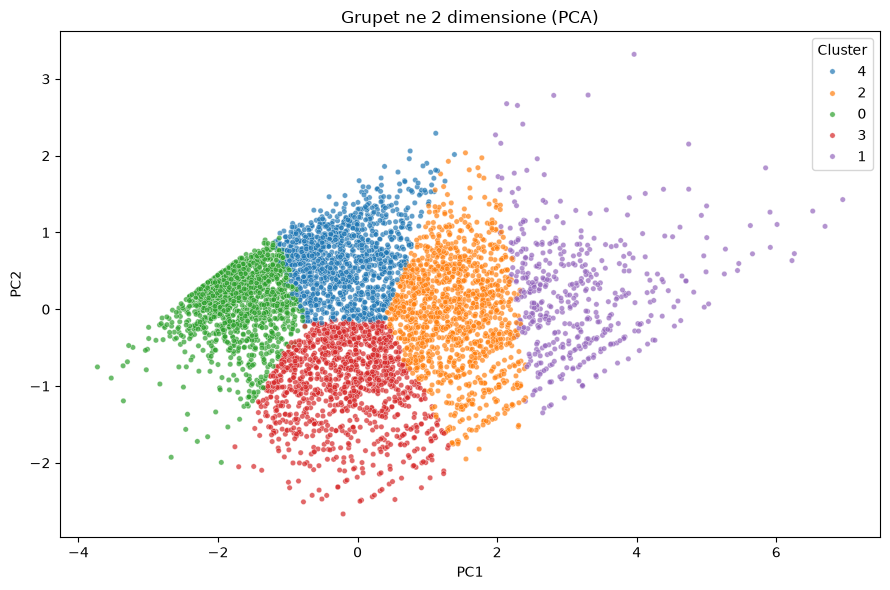

In [17]:
coords, pca = pca_2d(scaled)
print("Informacioni i ruajtur:", pca.explained_variance_ratio_.round(3),
        "| gjithsej:", round(pca.explained_variance_ratio_.sum(),3))

plot_df = coords.join(labels5.astype(str))
plt.figure(figsize=(9,6))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="Cluster", palette="tab10", s=15, alpha=0.7)
plt.title("Grupet ne 2 dimensione (PCA)")
plt.tight_layout()
plt.show()

In [19]:
final = final_segmentation(rfm)
final_profile = profile_cluster(rfm, final["Segment"]).sort_values("Te_ardhurat", ascending=False)
final_profile

,Klientet,Recency_mediana,Freuqency_mediana,Monetary_mediana,Te_ardhurat,Pjesa_e_klienteve_%,Pjesa_e_te_ardhurave_%
Segment,,,,,,,
VIP,467,9.00,23.00,"9,763.20","9,527,870.40",8.00,55.80
Champions,1286,30.00,8.00,"2,771.30","4,327,632.40",22.00,25.40
At risk,1335,258.00,4.00,"1,117.00","2,056,580.00",22.80,12.00
Recent,1129,30.00,2.00,554.60,"713,682.60",19.30,4.20
Lost,1635,418.00,1.00,239.50,"442,802.60",27.90,2.60


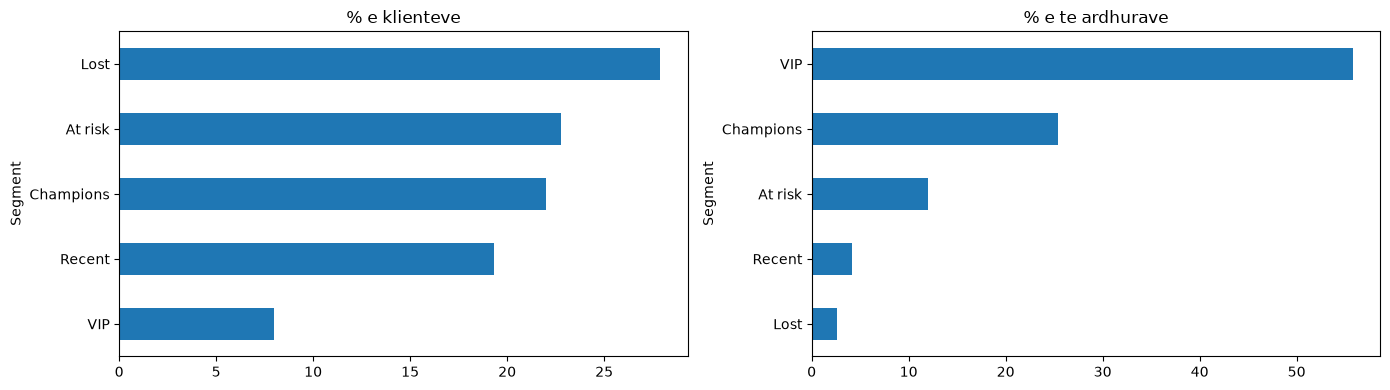

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
final_profile["Pjesa_e_klienteve_%"].sort_values().plot.barh(ax=axes[0], title="% e klienteve")
final_profile["Pjesa_e_te_ardhurave_%"].sort_values().plot.barh(ax=axes[1], title="% e te ardhurave")
plt.tight_layout()
plt.show()

## Segmentet perfundimtare dhe rekomandime per biznesin (k = 5)

| Segment | Kliente | % e klienteve | Te ardhurat (milion £) | % e te ardhurave | Recency (mediana, dite) | Frequency (mediana, fatura) | Monetary (mediana, £) |
|---|---|---|---|---|---|---|---|
| VIP | 467 | 8.0% | 9.53 | 55.8% | 9 | 23 | 9,763.20 |
| Champions | 1,286 | 22.0% | 4.33 | 25.4% | 30 | 8 | 2,771.30 |
| At risk | 1,335 | 22.8% | 2.06 | 12.0% | 258 | 4 | 1,117.00 |
| Recent | 1,129 | 19.3% | 0.71 | 4.2% | 30 | 2 | 554.60 |
| Lost | 1,635 | 27.9% | 0.44 | 2.6% | 418 | 1 | 239.50 |

Te ardhurat gjithsej te klienteve me ID: rreth 17.07 milion £.

**Vezhgime**
- VIP jane vetem 8.0% e klienteve por sjellin 55.8% te te ardhurave. Mediana e shpenzimeve te tyre (9,763 £) eshte rreth 3.5 here ajo e Champions dhe rreth 41 here ajo e Lost. Brenda VIP mesatarja (rreth 20,400 £) eshte dy here mediana, pra ka disa kliente jashtezakonisht te medhenj.
- VIP dhe Champions se bashku jane 30.0% e klienteve dhe sjellin 81.2% te te ardhurave. Pra biznesi mbeshtetet te nje pakice klientesh.
- At risk dhe Lost jane gjysma e klienteve (50.7%) por sjellin vetem 14.6% te te ardhurave.
- Recent kane te njejten mediane te Recency si Champions (30 dite), por vetem 2 fatura ne mediane kundrejt 8. Pra jane kliente te fresket qe ende nuk kane krijuar zakon blerjeje.
- At risk kane mediane 258 dite (rreth 8.5 muaj) pa blere, por 4 fatura ne mediane dhe 2.06 milion £ te shpenzuara gjithsej, pra kane historik blerjesh qe vlen te riaktivizohet.
- Lost kane mediane 418 dite pa blere dhe vetem 1 fature, pra shumica blene nje here dhe nuk u kthyen.

**Cfare duhet te bej biznesi me secilin segment**
- **VIP (467 kliente):** sjellin pjesen me te madhe te te ardhurave. Duhet trajtim personal: kontakt direkt, qasje e hershme ne produkte te reja, program besnikerie. Prioriteti kryesor eshte te mos humbasin, sepse humbja e nje prej tyre ka efekt te madh.
- **Champions (1,286 kliente):** blejne shpesh dhe shpenzojne shume. Sugjerim: oferta per blerje me shumice, rekomandime produktesh te lidhura, ftese per te sjelle kliente te rinj, dhe nje rruge per t'i çuar disa prej tyre drejt VIP.
- **At risk (1,335 kliente):** mundesia me e mire per fitim te shpejte. Nje fushate kthimi (kujtese, oferte e personalizuar bazuar ne blerjet e meparshme) mund t'i rikthejne te Champions ose Recent.
- **Recent (1,129 kliente):** qellimi eshte blerja e dyte dhe e treta. Email falenderimi, rekomandim produktesh sipas blerjes se pare, nje stimul i vogel brenda disa javeve.
- **Lost (1,635 kliente):** shume kliente por pak te ardhura. Vlen vetem nje riaktivizim me kosto te ulet (p.sh. email sezonal), pa investime te medha.

**Kufizime**
- Segmentet jane ndertuar nga sjellja e blerjes ne periudhen 2009-2011 dhe nuk marrin parasysh produktet, shtetin apo kthimet.
- Grupet kalojne ngadale nga njeri ne tjetrin (shih grafikun PCA), jo me kufij te mprehte, dhe silhouette eshte 0.35, pra ndarje e arsyeshme por jo e forte.
- Emrat varen nga random_state = 42 dhe nga ky dataset. Nese ndryshojne te dhenat, emrat duhen verifikuar perseri.